In [1]:
import sys
import os

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, os.path.join(REPO_ROOT, 'code'))

import numpy as np
import pandas as pd

from scunit import ScUnit
from analysis_tools import *

# between-cluster signature testing

In [2]:
COSMIC_PATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'))
cosmic = pd.read_csv(COSMIC_PATH, sep = '\t').set_index('Type').T

breast_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a', 'SBS17b', 'SBS18', 'SBS37', 'SBS40a', 'SBS40b', 'SBS40c', 'SBS41']

In [3]:
FILEPATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/funnell2022single-SA1035.csv'))
Y = ScUnit(FILEPATH, min_mutations=50)

Loaded 2586 cells.
Mutations per cell:
	min:  54
	mean: 663
	max:  4610


Silhouette: 0.9012
DBCV: 0.9622


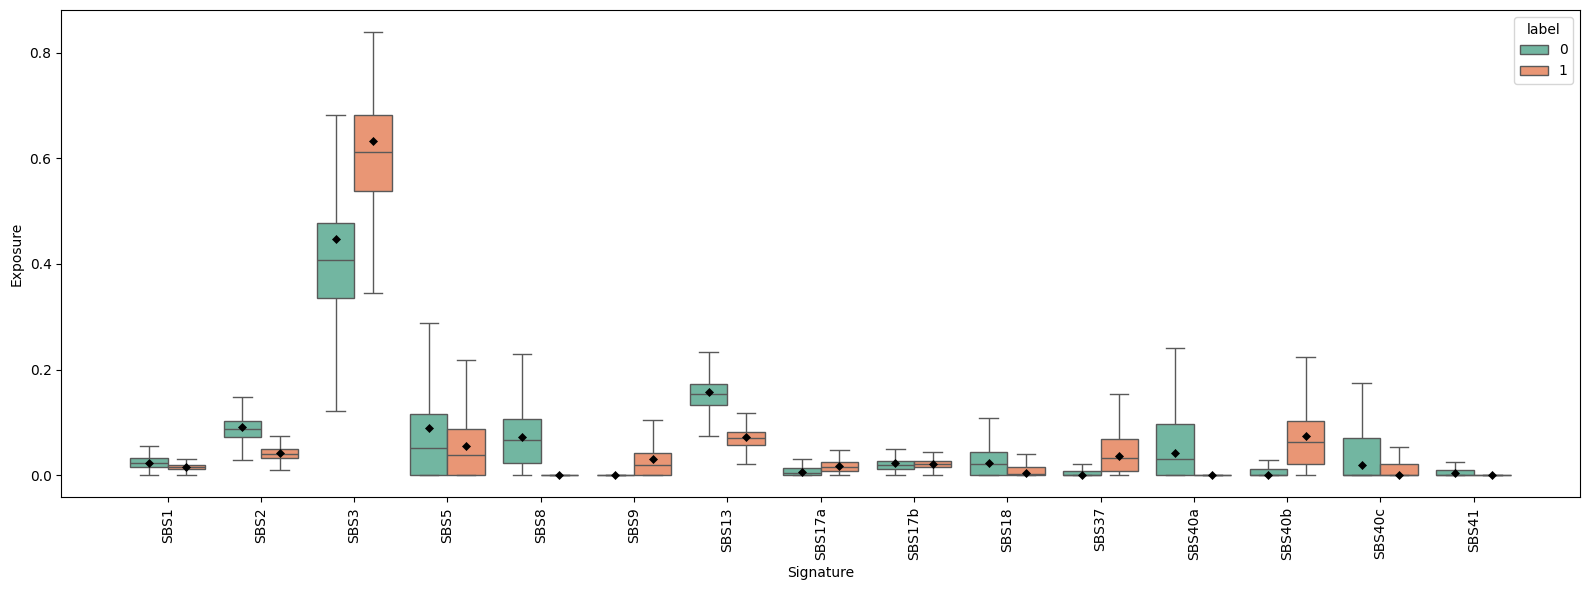

In [4]:
Y.umap().hdbscan().plot_exposures(signatures=cosmic.loc[breast_sigs].T)

In [5]:
labels = Y.umap().hdbscan().get_labels()
exposures = Y.deconv(signatures=cosmic.loc[breast_sigs].T)

In [6]:
test_signature_exposures(exposures, labels)

,stat,eta_squared,p_value,p_value_bh
SBS1,35.091964,0.119343,3.144960e-09,3.369600e-09
SBS2,275.266029,0.538650,8.076838e-62,1.514407e-61
SBS3,152.347195,0.462360,5.320403e-35,7.980604e-35
SBS5,1.131608,0.012985,2.874325e-01,2.874325e-01
SBS8,1182.086333,0.319154,4.769392e-259,7.154088e-258
SBS9,761.918444,0.234414,1.027850e-167,3.854438e-167
SBS13,305.492108,0.669736,2.095374e-68,4.490088e-68
SBS17a,484.510886,0.151543,2.229433e-107,5.573581e-107
SBS17b,59.346628,0.008235,1.322065e-14,1.652582e-14
SBS18,185.009741,0.110764,3.905453e-42,6.509088e-42


In [7]:
test_signature_exposures(exposures, labels, clr_transform=False)

,stat,eta_squared,p_value,p_value_bh
SBS1,370.295733,0.119343,1.613630e-82,2.420445e-82
SBS2,1440.209719,0.538650,0.000000e+00,0.000000e+00
SBS3,1239.657711,0.462360,1.467871e-271,7.339354e-271
SBS5,15.245127,0.012985,9.442008e-05,9.442008e-05
SBS8,1094.073332,0.319154,6.412323e-240,2.404621e-239
SBS9,782.639901,0.234414,3.210043e-172,6.878663e-172
SBS13,1609.812070,0.669736,0.000000e+00,0.000000e+00
SBS17a,478.993880,0.151543,3.537315e-106,5.895524e-106
SBS17b,23.260295,0.008235,1.414910e-06,1.515975e-06
SBS18,274.353938,0.110764,1.276483e-61,1.740658e-61


# distances and hierarchical clustering

In [36]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
import matplotlib.pyplot as plt
import seaborn as sns

def pairwise_cosine(df):
    return pd.DataFrame(
        cosine_similarity(df.values),
        index=df.index,
        columns=df.index
    )

def plot_cosine_heatmap(df, figsize=(10, 10), title=None):
    sim = pairwise_cosine(df)
    # hierarchical clustering to sort rows/columns
    order = leaves_list(linkage(sim.values, method='average'))
    sim_sorted = sim.iloc[order, order]
    
    plt.figure(figsize=figsize)
    sns.heatmap(sim_sorted, cmap='viridis', xticklabels=False, yticklabels=False)
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()

def hierarchical_clustering(df, n_clusters, method='ward', metric='euclidean'):
    df_norm = df.div(df.sum(axis=1), axis=0)
    Z = linkage(df_norm.values, method=method, metric=metric)
    labels = fcluster(Z, n_clusters, criterion='maxclust') - 1  # zero-indexed
    return pd.Series(labels, index=df.index, name='cluster_label')    

In [11]:
exposures = Y.deconv(signatures=cosmic.loc[breast_sigs].T)
exposures.head()

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a,SBS17b,SBS18,SBS37,SBS40a,SBS40b,SBS40c,SBS41
cell_id,,,,,,,,,,,,,,,
SA1035X4XB02879-A95626A-R03-C22,0.016505,0.116008,0.373652,0.079604,0.082105,0.001068,0.181576,0.001763,0.015147,0.000000,0.0,0.089838,0.009843,0.000000,0.032892
SA1035X4XB02879-A95626A-R03-C24,0.030030,0.088916,0.485862,0.000000,0.075066,0.000000,0.169174,0.003695,0.013031,0.030635,0.0,0.085833,0.000000,0.000000,0.017758
SA1035X4XB02879-A95626A-R03-C31,0.016706,0.124863,0.336249,0.096864,0.104948,0.000000,0.174069,0.009296,0.018417,0.011391,0.0,0.026029,0.081168,0.000000,0.000000
SA1035X4XB02879-A95626A-R03-C37,0.028653,0.072179,0.399525,0.000000,0.069310,0.016530,0.142543,0.012628,0.030155,0.045306,0.0,0.047861,0.000000,0.135309,0.000000
SA1035X4XB02879-A95626A-R03-C44,0.017512,0.099452,0.507809,0.000000,0.062098,0.000000,0.157935,0.013389,0.006729,0.046243,0.0,0.083432,0.000000,0.005402,0.000000


In [12]:
Y.df_mutations.head()

,A[C>A]A,A[C>A]C,A[C>A]G,A[C>A]T,A[C>G]A,A[C>G]C,A[C>G]G,A[C>G]T,A[C>T]A,A[C>T]C,...,T[T>A]G,T[T>A]T,T[T>C]A,T[T>C]C,T[T>C]G,T[T>C]T,T[T>G]A,T[T>G]C,T[T>G]G,T[T>G]T
cell_id,,,,,,,,,,,,,,,,,,,,,
SA1035X4XB02879-A95626A-R03-C22,8,9,0,10,1,4,4,6,7,5,...,2,4,3,5,2,5,2,1,2,6
SA1035X4XB02879-A95626A-R03-C24,16,9,1,13,13,4,4,5,6,7,...,3,6,6,6,2,5,2,2,3,7
SA1035X4XB02879-A95626A-R03-C31,12,7,0,5,4,2,2,6,6,3,...,2,9,2,4,3,4,3,0,5,6
SA1035X4XB02879-A95626A-R03-C37,6,7,3,15,6,0,5,7,4,5,...,4,7,4,5,3,6,3,1,3,9
SA1035X4XB02879-A95626A-R03-C44,11,10,2,11,9,4,8,9,6,3,...,3,7,6,3,1,8,4,6,3,3


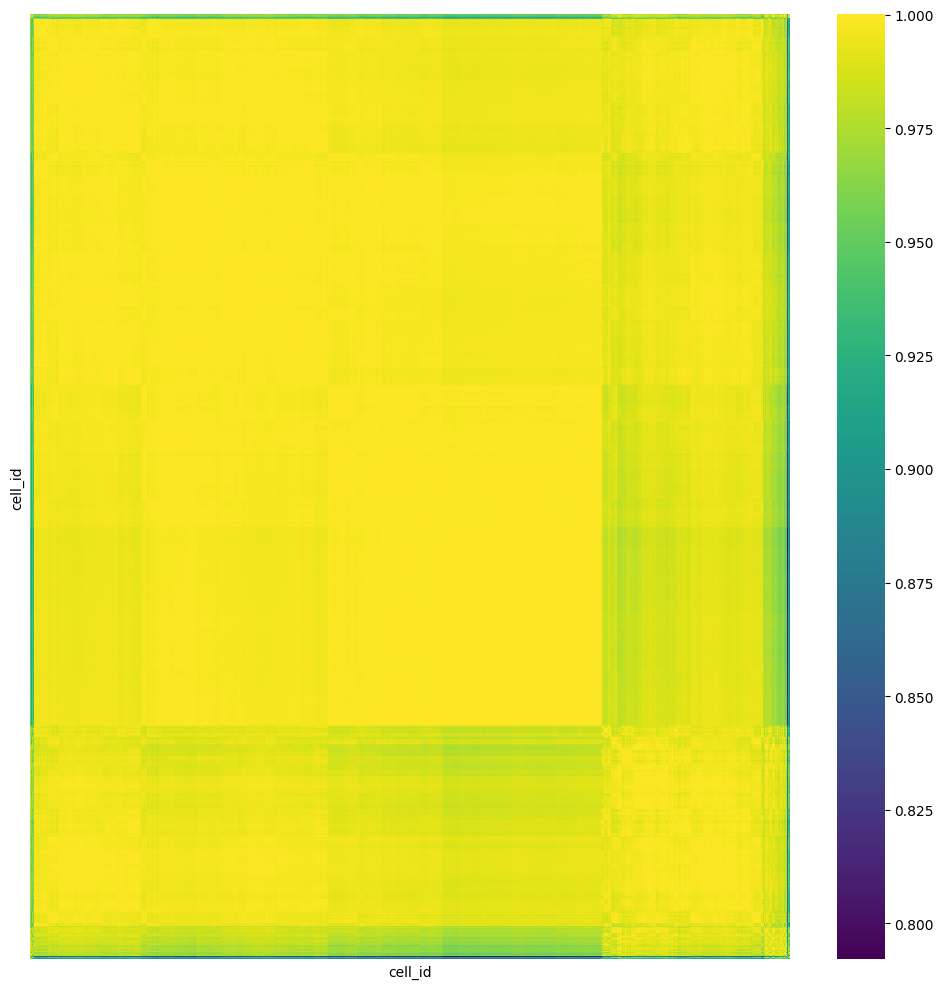

In [24]:
exposures_dist = pairwise_cosine(exposures)
plot_cosine_heatmap(exposures_dist)

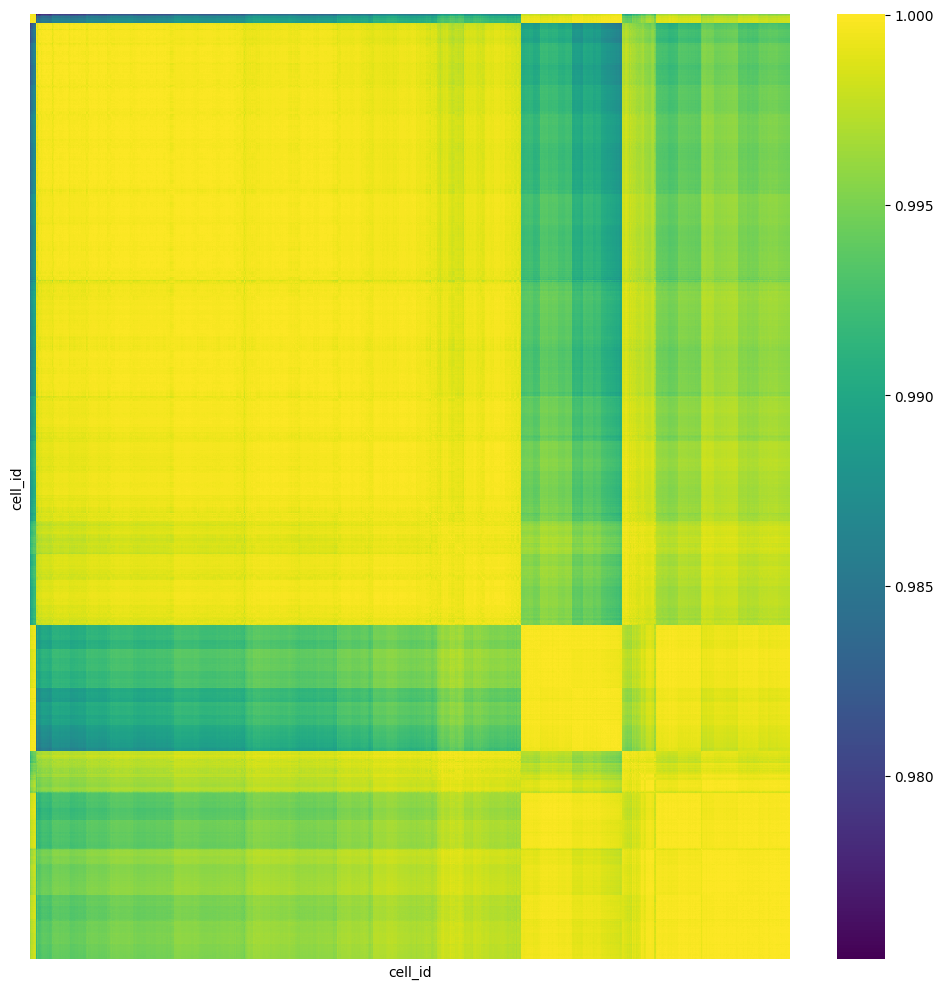

In [25]:
mutations_dist = pairwise_cosine(Y.df_mutations)
plot_cosine_heatmap(mutations_dist)

In [37]:
labels_hierarchical = hierarchical_clustering(Y.df_mutations, n_clusters=2)

In [38]:
crosstable(labels_hierarchical.values, labels)

Cluster B,0,1
Cluster A,,
0,0,854
1,1708,24


# laks et al. joint analysis

In [40]:
dfs = []
labels = []
for path in paths:
    df = pd.read_csv(path).set_index('cell_id')
    sample_id = os.path.basename(path).replace('.csv', '')
    dfs.append(df)
    labels.append(pd.Series(sample_id, index=df.index, name='sample'))

combined = pd.concat(dfs)
sample_labels = pd.concat(labels)

combined.to_csv(os.path.abspath(os.path.join(os.getcwd(), '../../data/combined.csv')))

In [39]:
paths = [
    os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/laks2021clonal-SA921.csv')),
    os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/laks2021clonal-SA922.csv')),
    os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/laks2021clonal-SA1090.csv'))
]

In [49]:
FILEPATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/combined.csv'))
L = ScUnit(FILEPATH, min_mutations=0)

Loaded 1869 cells.
Mutations per cell:
	min:  1
	mean: 490
	max:  1242


Silhouette: 0.5922
DBCV: 0.6704


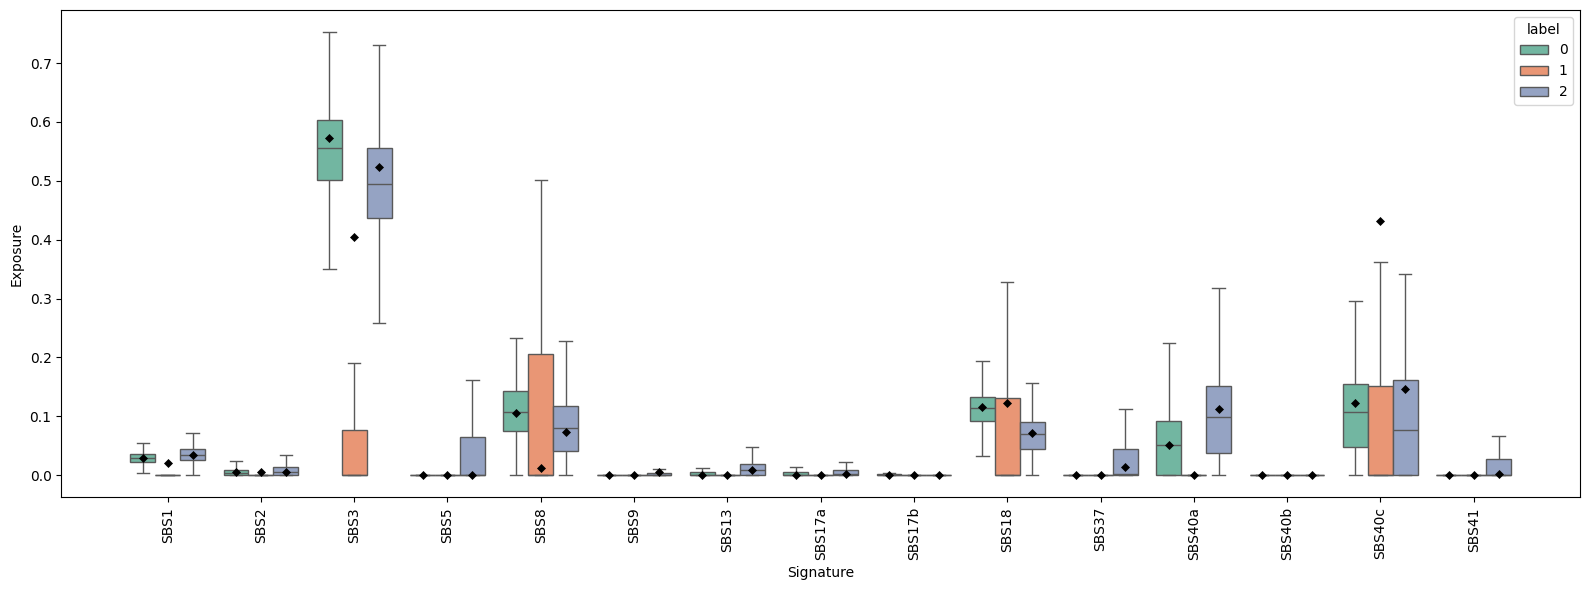

In [50]:
L.umap().hdbscan().plot_exposures(signatures=cosmic.loc[breast_sigs].T)

In [51]:
labels = L.umap().hdbscan().get_labels()

In [52]:
crosstable(labels.values, sample_labels.values)

Cluster B,laks2021clonal-SA1090,laks2021clonal-SA921,laks2021clonal-SA922
Cluster A,,,
-1,1,1,4
0,12,489,17
1,22,77,93
2,699,14,440
